# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [102]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [103]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')#completa el código

In [69]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [70]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [43]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [44]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [45]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [46]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [47]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [48]:
# cantidad de nulos para users

print("Cantidad de valores nulos:")
print(users.isna().sum())

print("\nProporción de valores nulos:")
print(users.isna().mean())

Cantidad de valores nulos:
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de valores nulos:
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [35]:
# cantidad de nulos para usage
print("Cantidad de valores nulos en usage:")
print(usage.isna().sum())

# Proporción de valores nulos por columna
print("\nProporción de valores nulos en usage:")
print(usage.isna().mean())

Cantidad de valores nulos en usage:
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de valores nulos en usage:
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- users_latam.csv
- city tiene entre un 20–25% de faltantes.
lo cual indica que se deverian de imputar con “Desconocido” o agrupar en categoría especial, porque es clave para segmentación.

y churn_date tiene faltante de >80% de registros.
lo cual se deveria eliminar/ignorar, ya que la mayoría no tiene fecha de baja, probablemente usuarios activos.

age tiene valores inválidos -999 que son equivalentes a nulos.
se deveria de reemplazar por NaN y decidir imputación o eliminación según análisis de distribución.
- Indica qué harías: ¿imputar, eliminar, ignorar?
- usage.csv
Varias columnas de consumo como mensajes, GB, minutos, tienen nulos.
Si >90% nulos se eliminar columna.
Si 5–30% nulos se investigar e imputar (ej. con promedio del plan). 
Si <5% nulos se imputar fácilmente (ej. con 0 o media).

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
En users_latam, la columna crítica a limpiar es age (sentinels -999) y reg_date (outliers en 2026).
En plans, los valores son consistentes y no requieren limpieza.
El análisis muestra que los usuarios tienden a ser adultos mayores y que el plan Premium ofrece mejor costo por unidad.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.
Las columnas categóricas relevantes son plan y city.
plan está limpio y bien definido.
city requiere limpieza por valores inválidos.
Los nombres y apellidos son repetitivos y no aportan valor analítico, salvo para detectar duplicados.
El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [49]:
# explorar columnas numéricas de users
print(users.describe())

            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000


- En la columna `user_id` Se observa que user_id es un identificador secuencial que va de 10,000 a 13,999.
Tiene 4,000 registros en total, con media cercana a 11,999 y desviación estándar de ~1,154.
No presenta problemas, es simplemente un ID único para cada usuario.
- La columna `age` tiene 4,000 registros, pero el mínimo es -999, lo cual es un sentinel (valor inválido que representa dato faltante).
La media está distorsionada (33.7) y la desviación estándar es muy alta (123) debido a esos valores erróneos.
El rango válido parece estar entre 18 y 79 años, con percentiles que muestran concentración en adultos (32 años en el 25%, 47 en el 50%, y 63 en el 75%).
Acción necesaria: reemplazar -999 por NaN para limpiar la columna y obtener estadísticas reales.

In [53]:
# explorar columnas numéricas de usage
print(usage.describe())

                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000


- Las columnas `id` y `user_id` se muestra que id Va de 1 a 40,000, con media en 20,000.
Es simplemente un identificador único para cada registro de uso.
No presenta problemas, es un índice secuencial. y la columna de user_id Va de 10,000 a 13,999, con media cercana a 12,002.
Coincide con los IDs de usuarios en users_latam.csv, lo que permite relacionar consumo con características de cada usuario.
Distribución uniforme, sin valores fuera de rango.

In [71]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

# Valores únicos y conteo por categoría
for col in columnas_user:
    print(f"\nValores únicos en {col}:")
    print(users[col].unique())
    print(f"\nConteo de cada categoría en {col}:")
    print(users[col].value_counts(dropna=False))


Valores únicos en city:
['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']

Conteo de cada categoría en city:
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Valores únicos en plan:
['Basico' 'Premium']

Conteo de cada categoría en plan:
Basico     2595
Premium    1405
Name: plan, dtype: int64


- La columna `city` muestra varias ciudades válidas pero también contiene valores faltantes (NaN) y sentinels (?).
requiere limpieza, reemplazando ? y vacíos por NaN o imputando como “Desconocido” para poder segmentar correctamente por ubicación.
- La columna `plan` tiene solo dos categorías (Basico y Premium), con mayor proporción de usuarios en el plan Basico (2595 vs 1405).
está limpia y bien definida, lista para análisis de segmentación y comparación de consumo/ingresos entre planes.

In [73]:
# explorar columna categórica de usage
#usage['type'] # completa el código
print("Valores únicos en type:")
print(usage['type'].unique())

print("\nConteo de cada categoría en type:")
print(usage['type'].value_counts(dropna=False))

Valores únicos en type:
['call' 'text']

Conteo de cada categoría en type:
text    22092
call    17908
Name: type, dtype: int64


- La columna `type` la proporción es ligeramente mayor en text 55% frente a call 45%.
No aparecen valores nulos ni sentinels, lo que indica que la columna está limpia y bien definida.
Esta variable es clave para segmentar el análisis de consumo: por ejemplo, comparar duración de llamadas vs longitud de mensajes, o ver qué tipo de uso predomina en cada plan.

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
Los principales sentinels están en users_latam (-999, ?, notación científica, fechas fuera de rango).
En usage, hay que vigilar outliers y posibles negativos.
En plans, no hay problemas.
- ¿Qué acción tomarías?
age el valor -999  
Sentinel que representa dato faltante.
Acción: reemplazar por NaN y luego imputar o eliminar según el caso.

city los valores ? y vacíos (NaN)
No son ciudades válidas.
Acción: reemplazar por NaN o agrupar como “Desconocido”.

churn_date los valores en notación científica (1,71832E+18)
Error de conversión de fechas.
Acción: reemplazar por NaN o eliminar la columna si >80% nulos.

reg_date las fechas fuera de rango (ej. 2026 cuando la mayoría son de 2022).
Outliers por error de carga.
Acción: revisar y corregir, o marcar como outliers.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [74]:
# Convertir a fecha la columna `reg_date` de users
#users['reg_date'] = # completa el código
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

# Verificar el cambio
print(users.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     4000 non-null   int64         
 1   first_name  4000 non-null   object        
 2   last_name   4000 non-null   object        
 3   age         4000 non-null   int64         
 4   city        3531 non-null   object        
 5   reg_date    4000 non-null   datetime64[ns]
 6   plan        4000 non-null   object        
 7   churn_date  466 non-null    object        
dtypes: datetime64[ns](1), int64(2), object(5)
memory usage: 250.1+ KB
None


In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = # completa el código

In [75]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

# Revisar los años presentes
print("Años únicos en reg_date:")
print(users['reg_date'].dt.year.unique())

Años únicos en reg_date:
[2022 2026 2023 2024]


En `reg_date`, se observa una lista de los años únicos en los que se registraron usuarios.
Según lo que vimos antes, la mayoría de registros son de 2022, aunque también aparecen algunos valores atípicos en 2026 (probablemente errores de carga).

In [76]:
# Revisar los años presentes en `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

# Revisar los años presentes
print("Años únicos en date:")
print(usage['date'].dt.year.unique())

# Conteo por año
print("\nConteo de registros por año:")
print(usage['date'].dt.year.value_counts())

Años únicos en date:
[2024.   nan]

Conteo de registros por año:
2024.0    39950
Name: date, dtype: int64


En `date`, lo que se observa es que todo el consumo registrado corresponde al año 2024.
Valores faltantes: los NaN deben tratarse como registros sin fecha válida, se pueden eliminar o marcar como “desconocido”.
Cruce con reg_date de users: esto nos permitirá analizar qué cohortes de registro (ej. usuarios registrados en 2022) generaron actividad en 2024.
Con esto, el análisis se centrará en usuarios activos en 2024, independientemente de cuándo se registraron.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
En users.reg_date vimos registros con año 2026, cuando la mayoría son de 2022.
Esto es un año sin transcurrir al momento de guardar los datos, por lo tanto es un outlier o error de carga.
En usage.date solo aparece 2024, lo cual es consistente, pero también hay algunos valores faltantes (NaN).
No hay años viejos ni futuros aquí, solo nulos que deben tratarse.

- ¿Qué harías con ellas?

Fechas futuras (ej. 2026 en reg_date):
Reemplazarlas por NaT (NaN para fechas) usando errors='coerce en pd.to_datetime.
O bien, filtrarlas si quieres quedarte solo con registros válidos (ej. usuarios registrados hasta 2024).

Fechas muy viejas o fuera de rango (si aparecieran):
Validar contra el rango esperado (ej. registros a partir de 2020).
Si no cumplen, marcarlas como inválidas y excluirlas del análisis.

Valores faltantes (NaN):
Decidir si se imputan (ej. con fecha promedio de registro) o se eliminan, según el peso que tengan en el dataset.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [77]:
# Reemplazar -999 por la mediana de age
#age_mediana = ...
#users['age'] = ...
# Sentinel en age: reemplazar -999 con la mediana
mediana_age = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, mediana_age)
# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [79]:
# Reemplazar ? por NA en city
# Sentinel en city: reemplazar "?" por valores nulos
users['city'] = users['city'].replace("?", pd.NA)

# Verificar cambios
users['city'].describe()

count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [80]:
# Marcar fechas futuras como NA para reg_date
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')
# Verificar cambios
users['reg_date'].describe()

count                    4000
unique                   3961
top       2026-05-10 00:00:00
freq                       40
first     2022-01-01 00:00:00
last      2026-05-10 00:00:00
Name: reg_date, dtype: object

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [81]:
# Verificación MAR en usage (Missing At Random) para duration
usage.groupby('type')['duration'].apply(lambda x: x.isna().mean())

type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [82]:
# Verificación MAR en usage (Missing At Random) para length
usage.groupby('type')['length'].apply(lambda x: x.isna().mean())

type
call    0.99933
text    0.00000
Name: length, dtype: float64

Nulos en `duration` y `length`

duration
Los nulos aparecen únicamente en registros con type = "text".
Justificación: los mensajes no tienen duración en minutos, por lo que la ausencia de datos es natural.
Conclusión: los nulos dependen de type, son MAR (Missing At Random) y deben mantenerse como nulos.

length
Los nulos aparecen únicamente en registros con type = "call".
Justificación: las llamadas no tienen longitud en caracteres, por lo que la ausencia de datos es esperada.
Conclusión: los nulos dependen de type, son MAR (Missing At Random) y deben mantenerse como nulos.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [85]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas
# Agrupar información por usuario
#usage_agg = usage ... reset_index()
# observar resultado
#usage_agg.head(3)
# Agrupar información por usuario
usage_agg = (
    usage.groupby('user_id')
    .agg(
        cant_mensajes = ('is_text', 'sum'),
        cant_llamadas = ('is_call', 'sum'),
        cant_minutos_llamada = ('duration', 'sum')
    )
    .reset_index()
)
# Observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [86]:
# Renombrar columnas
usage_agg = usage_agg.rename(
    columns={
        'is_text': 'cant_mensajes',
        'is_call': 'cant_llamadas',
        'duration': 'cant_minutos_llamada'
    }
)
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [87]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [88]:
# Resumen estadístico de las columnas numéricas
print("Resumen estadístico de columnas numéricas:")
print(users[['age']].describe())

Resumen estadístico de columnas numéricas:
               age
count  4000.000000
mean     48.136000
std      17.689919
min      18.000000
25%      33.000000
50%      48.000000
75%      63.000000
max      79.000000


In [89]:
# Distribución porcentual del tipo de plan
print("\nDistribución porcentual de plan:")
print(users['plan'].value_counts(normalize=True) * 100)


Distribución porcentual de plan:
Basico     64.875
Premium    35.125
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

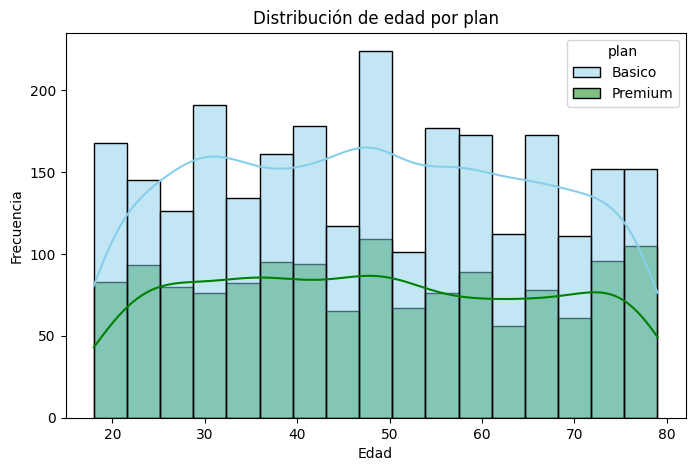

In [91]:
# Histograma para visualizar la edad (age)
#sns.histplot(...)
#plt.show()
plt.figure(figsize=(8,5))
sns.histplot(data=user_profile, x="age", hue="plan", palette=['skyblue','green'], kde=True)
plt.title("Distribución de edad por plan")
plt.xlabel("Edad")
plt.ylabel("Frecuencia")
plt.show()

💡Insights: 
Edad (age): Los usuarios del plan Premium tienden a concentrarse en rangos de edad más adultos, mientras que los del Básico muestran mayor dispersión.
La distribución suele ser sesgada a la derecha (más jóvenes, menos seniors).

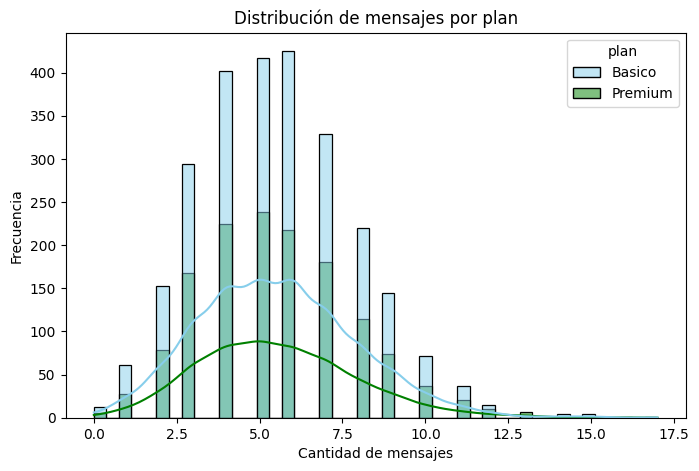

In [92]:
# Histograma para visualizar la cant_mensajes
plt.figure(figsize=(8,5))
sns.histplot(data=user_profile, x="cant_mensajes", hue="plan", palette=['skyblue','green'], kde=True)
plt.title("Distribución de mensajes por plan")
plt.xlabel("Cantidad de mensajes")
plt.ylabel("Frecuencia")
plt.show()

💡Insights: 
Mensajes (cant_mensajes)
En el plan Básico se observa mayor proporción de usuarios con volúmenes bajos de mensajes.
En el plan Premium hay más usuarios con altos volúmenes de mensajes.
Distribución sesgada a la derecha (muchos con pocos mensajes, pocos con muchísimos).

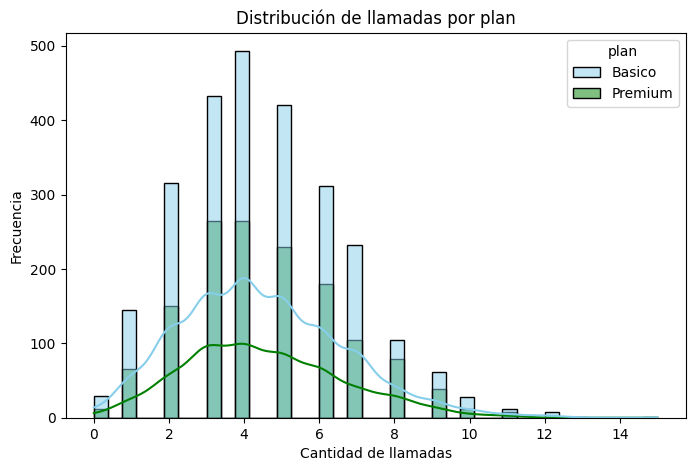

In [93]:
# Histograma para visualizar la cant_llamadas
plt.figure(figsize=(8,5))
sns.histplot(data=user_profile, x="cant_llamadas", hue="plan", palette=['skyblue','green'], kde=True)
plt.title("Distribución de llamadas por plan")
plt.xlabel("Cantidad de llamadas")
plt.ylabel("Frecuencia")
plt.show()

💡Insights: 
Llamadas (cant_llamadas)
Los usuarios Premium tienden a realizar más llamadas que los Básico.
Distribución también sesgada a la derecha (la mayoría hace pocas llamadas, unos pocos hacen muchas).

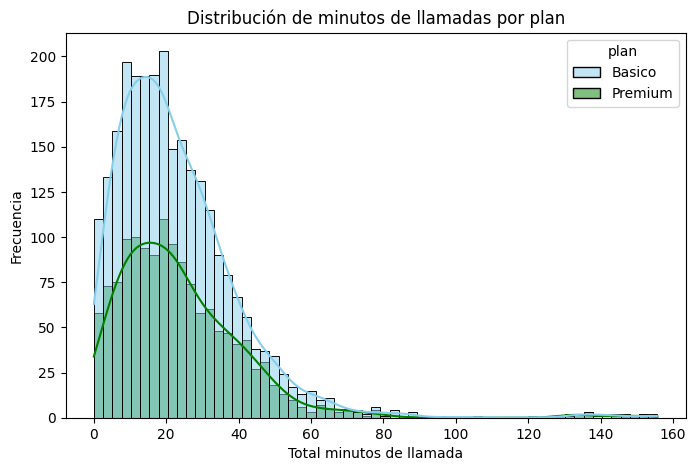

In [94]:
# Histograma para visualizar la cant_minutos_llamada
plt.figure(figsize=(8,5))
sns.histplot(data=user_profile, x="cant_minutos_llamada", hue="plan", palette=['skyblue','green'], kde=True)
plt.title("Distribución de minutos de llamadas por plan")
plt.xlabel("Total minutos de llamada")
plt.ylabel("Frecuencia")
plt.show()

💡Insights: 
Minutos de llamadas (cant_minutos_llamada)
En Premium se concentran los usuarios con mayor tiempo acumulado en llamadas.
En Básico predominan los usuarios con pocos minutos.
Distribución sesgada a la derecha (pocos usuarios concentran muchos minutos).

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

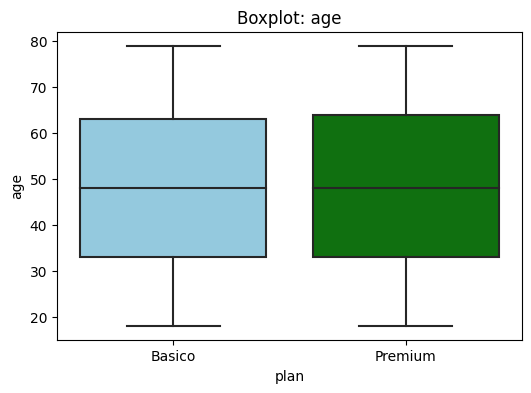

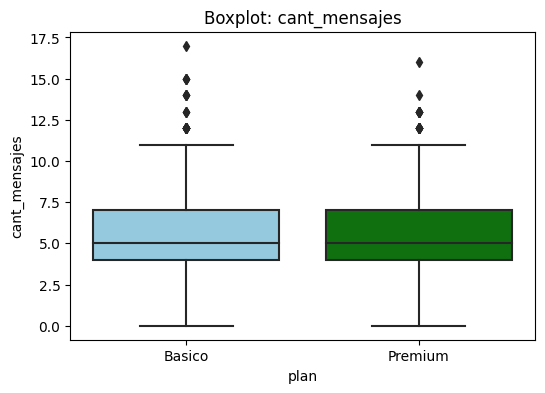

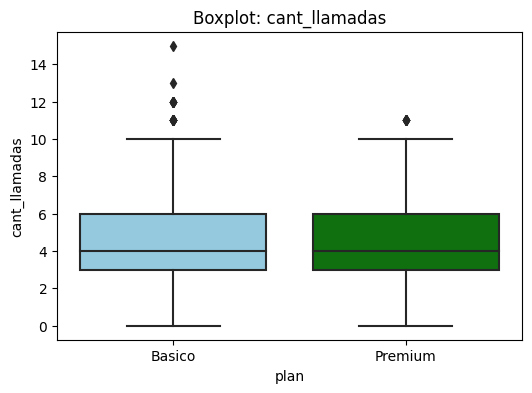

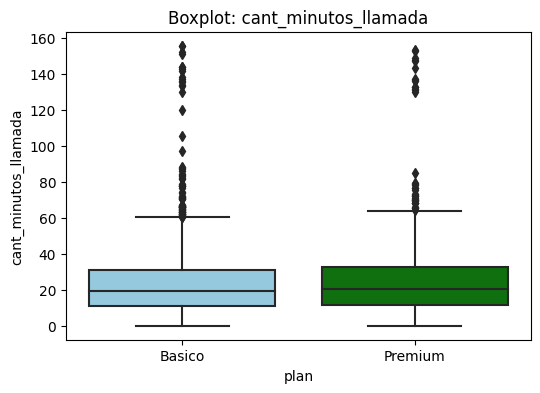

In [95]:
# Visualizando usando BoxPlot 
#columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
# Columnas a analizar
cols = ["age", "cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]

# Crear boxplots en un bucle
for col in cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(data=user_profile, x="plan", y=col, palette=['skyblue','green'])
    plt.title(f'Boxplot: {col}')
    plt.show()

💡Insights: 
- Age: se observan algunos valores extremos (ej. edades muy altas o fuera de rango).
- cant_mensajes: distribución sesgada a la derecha, con usuarios que envían cantidades muy altas de mensajes outliers.
- cant_llamadas: también sesgada a la derecha, con pocos usuarios que realizan muchísimas llamadas.
- cant_minutos_llamada: fuerte sesgo a la derecha, con outliers de usuarios que acumulan miles de minutos.

In [97]:
# Calcular límites con el método IQR
for col in cols:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    
    # Límites
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    
    print(f"{col}:")
    print(f"  Q1={Q1}, Q3={Q3}, IQR={IQR}")
    print(f"  Límite inferior={lower_limit}, Límite superior={upper_limit}")
    print(f"  Valores fuera de rango: {(user_profile[col] < lower_limit).sum()} abajo, {(user_profile[col] > upper_limit).sum()} arriba\n")


age:
  Q1=33.0, Q3=63.0, IQR=30.0
  Límite inferior=-12.0, Límite superior=108.0
  Valores fuera de rango: 0 abajo, 0 arriba

cant_mensajes:
  Q1=4.0, Q3=7.0, IQR=3.0
  Límite inferior=-0.5, Límite superior=11.5
  Valores fuera de rango: 0 abajo, 46 arriba

cant_llamadas:
  Q1=3.0, Q3=6.0, IQR=3.0
  Límite inferior=-1.5, Límite superior=10.5
  Valores fuera de rango: 0 abajo, 30 arriba

cant_minutos_llamada:
  Q1=11.12, Q3=31.415, IQR=20.295
  Límite inferior=-19.322500000000005, Límite superior=61.8575
  Valores fuera de rango: 0 abajo, 109 arriba



In [99]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
#user_profile[columnas_limites].describe()
# Columnas a revisar
columnas_limites = ["age", "cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]

# Resumen estadístico para ver min, max, media, etc.
user_profile[columnas_limites].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
- cant_llamadas: mantener o no outliers, porqué?
- cant_minutos_llamada: mantener o no outliers, porqué?

age: revisar valores extremos (ej. >79 o negativos ya tratados). Si son errores de carga, marcarlos como nulos.

cant_mensajes, cant_llamadas, cant_minutos_llamada: los outliers son esperados en comportamiento de uso (usuarios muy intensivos).
No se eliminan, se mantienen, porque reflejan la realidad del consumo.
Solo se corrigen outliers imposibles (ej. edades fuera de rango).

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [106]:
# Crear columna grupo_uso
user_profile['grupo_uso'] = np.where(
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5), 'Bajo uso',
    np.where(
        (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10), 'Uso medio',
        'Alto uso'
    )
)
# Verificar resultado
#user_profile[['user_id','cant_mensajes','cant_llamadas','grupo_uso']].head(10)

In [107]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [108]:
# Crear columna grupo_edad
user_profile['grupo_edad'] = np.where(
    user_profile['age'] < 30, 'Joven',
    np.where(
        user_profile['age'] < 60, 'Adulto',
        'Adulto Mayor'
    )
)
# Verificar resultado
#user_profile[['user_id','age','grupo_edad']].head(10)

In [109]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

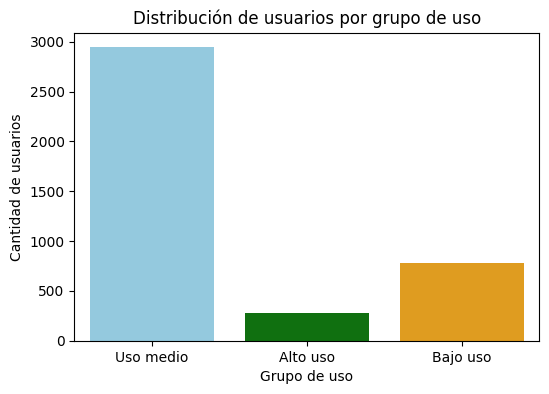

In [110]:
# Visualización de los segmentos por uso
#sns.countplot(...)
plt.figure(figsize=(6,4))
sns.countplot(data=user_profile, x="grupo_uso", palette=['skyblue','green','orange'])
plt.title("Distribución de usuarios por grupo de uso")
plt.xlabel("Grupo de uso")
plt.ylabel("Cantidad de usuarios")
plt.show()

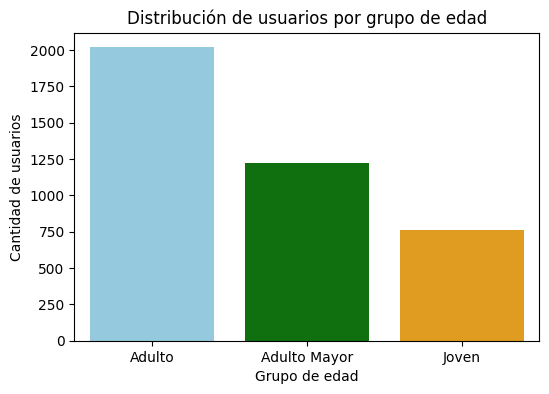

In [111]:
# Visualización de los segmentos por edad
plt.figure(figsize=(6,4))
sns.countplot(data=user_profile, x="grupo_edad", palette=['skyblue','green','orange'])
plt.title("Distribución de usuarios por grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Cantidad de usuarios")
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
Valores inválidos en edad (ej. -999), que representaban un porcentaje pequeño pero significativo de filas.
Ciudades faltantes o con sentinels (?) en la columna city.
Nulos en duration y length que resultaron ser MAR (Missing At Random), dependientes de type (mensajes vs llamadas).
Estos problemas afectaban la calidad del análisis inicial y requerían limpieza o imputación selectiva.

🔍 **Segmentos por Edad**
Por edad:
Jóvenes (<30)  mayor uso de mensajes, menor uso de llamadas.
Adultos (30–59)  balance entre mensajes y llamadas.
Adultos mayores (60+)  menor actividad en general, pero algunos casos de uso intensivo en llamadas.

📊 **Segmentos por Nivel de Uso**
Por nivel de uso:
Bajo uso: clientes con muy poca actividad, riesgo de churn alto.
Uso medio: clientes con actividad moderada, potencial de fidelización.
Alto uso: clientes con consumo intensivo, generan mayor ingreso.

➡️ Esto sugiere que vazado a la informacion obtenida todo esto implican que existen nichos de usuarios intensivos que podrían requerir planes especiales (ej. ilimitados o corporativos).

💡 **Recomendaciones**

Mejorar la oferta de planes:
Crear un plan intermedio entre Básico y Premium para captar usuarios de “Uso medio”.
Ofrecer planes ilimitados o corporativos para los outliers de alto consumo.

Segmentación comercial:
Campañas específicas para jóvenes intensivos en mensajes, migrarlos a Premium con beneficios en datos/mensajes.
Retención de adultos Premium de alto uso, programas de fidelización.

Prevención de churn:
Identificar usuarios de bajo uso y ofrecerles promociones o beneficios para aumentar su actividad.

Upselling y cross-selling:
Detectar usuarios Básico que exceden constantemente su consumo ofrecerles upgrade inmediato.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`